
[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Cloning into 'mm-bem'...
remote: Enumerating objects: 304, done.
remote: Counting objects: 100% (304/304), done.
remote: Compressing objects: 100% (303/303), done.
remote: Total 304 (delta 142), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (304/304), 11.97 MiB | 7.84 MiB/s, done.
Resolving deltas: 100% (142/142), done.
Angle	Backscattering length
0	0.0518485
1	0.0518184
2	0.0517279
3	0.0515774
4	0.0513674
5	0.0510983
6	0.0507712
7	0.050387
8	0.0499469
9	0.0494524


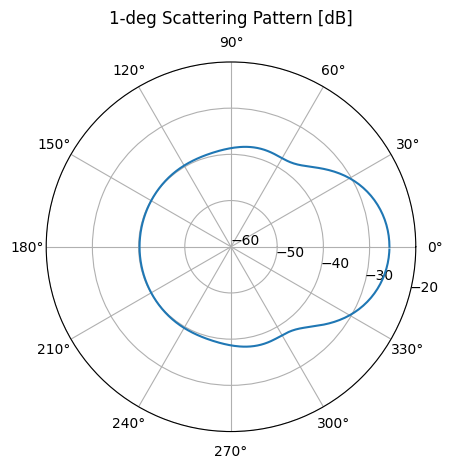

In [ ]:
!pip install -q numpy scipy matplotlib

import os
repo_name = "mm-bem"
repo_url = f"https://github.com/marmoszy/{repo_name}.git"

if not os.path.exists(repo_name):
    !git clone {repo_url}

os.chdir(f"{repo_name}/msh")

from numpy import pi, sqrt, exp, sin, cos, log10, array, zeros, linspace
from scipy.linalg import lu_factor, lu_solve
import matplotlib.pyplot as plt

fname = 'sphere-1.905-600.msh'
th = 0
f0 = 38e3
c0 = 1480

k = 2 * pi * f0 / c0
d = [cos(pi / 180 * th), sin(pi / 180 * th), 0]

with open(fname) as f: lines = f.readlines()
n = int(lines[4])
v = [list(map(float, lines[5 + i].split()[1:4])) for i in range(n)]
m = int(lines[n + 7])
e = [list(map(int, lines[n + 8 + i].split()[5:8])) for i in range(m)]

x = [sum([array(v[e[i][j] - 1]) / 3 for j in range(3)]) for i in range(m)]

S = zeros((m, m), dtype=complex)
for i in range(m):
    for j in range(m):
        r = sqrt(sum((x[i] - x[j]) ** 2))
        S[i][j] = exp(1j * k * r) / r / (4 * pi) if r != 0 else 1j * k / (4 * pi)

f_inc = array([exp(1j * k * p @ d) for p in x])

phi = lu_solve(lu_factor(S), -f_inc)

r1 = [[cos(pi / 180 * i), sin(pi / 180 * i), 0] for i in range(360)]
S_far = [[exp(-1j * k * p @ r) / (4 * pi) for p in x] for r in r1]
psc = S_far @ phi

print("Angle\tBackscattering length")
for i in range(10):
    print(f"{i}\t{abs(psc[i]):g}")

# Plot
angles = linspace(0, 2 * pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, label='Scattering Pattern (dB)')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title("Scattering Pattern [dB]", va='bottom')
plt.show()
